# Formative 2 – Part 1: Data Merge, Cleaning, Feature Engineering & EDA
**Owner:** Person 1 · **Goal:** build `merged_dataset.csv` to predict `product_category` from social + transaction data.

In [1]:
import sys, pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sys.path.append('../scripts')
import data_preprocessing as dp
sns.set_theme(style='whitegrid')
social_raw, trans_raw = dp.load_raw()
print(social_raw.shape, trans_raw.shape)

(155, 5) (150, 6)


## 1. Raw data inspection

In [2]:
display(social_raw.head()); display(trans_raw.head())
print(social_raw.dtypes, '\n'); print(trans_raw.dtypes)
print('\nNulls social:', social_raw.isna().sum().to_dict()); print('Nulls transactions:', trans_raw.isna().sum().to_dict())
print('\nExact duplicate rows  social:', social_raw.duplicated().sum(), '| transactions:', trans_raw.duplicated().sum())
display(social_raw.describe()); display(trans_raw.describe())

,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


customer_id_new                str
social_media_platform          str
engagement_score             int64
purchase_interest_score    float64
review_sentiment               str
dtype: object 

customer_id_legacy      int64
transaction_id          int64
purchase_amount         int64
purchase_date             str
product_category          str
customer_rating       float64
dtype: object

Nulls social: {'customer_id_new': 0, 'social_media_platform': 0, 'engagement_score': 0, 'purchase_interest_score': 0, 'review_sentiment': 0}
Nulls transactions: {'customer_id_legacy': 0, 'transaction_id': 0, 'purchase_amount': 0, 'purchase_date': 0, 'product_category': 0, 'customer_rating': 10}

Exact duplicate rows  social: 5 | transactions: 0


,engagement_score,purchase_interest_score
count,155.000000,155.000000
mean,75.606452,3.152903
std,14.568021,1.142867
min,50.000000,1.000000
25%,63.500000,2.350000
50%,77.000000,3.200000
75%,87.500000,4.100000
max,99.000000,5.000000


,customer_id_legacy,transaction_id,purchase_amount,customer_rating
count,150.000000,150.000000,150.000000,140.00000
mean,148.760000,1075.500000,280.780000,2.98500
std,30.046425,43.445368,121.329595,1.20699
min,100.000000,1001.000000,51.000000,1.00000
25%,121.250000,1038.250000,179.000000,1.95000
50%,150.500000,1075.500000,274.000000,3.00000
75%,174.750000,1112.750000,388.500000,4.00000
max,199.000000,1150.000000,495.000000,5.00000


**Findings**
- The two tables use **different ID formats**: `customer_id_new` is a string (`A178`) while `customer_id_legacy` is an int (`178`). Stripping the `A` prefix aligns them.
- Social table: **5 exact duplicate rows**; a customer can have several rows (one per platform/profile) → many-to-one relationship.
- Transactions: **10 missing `customer_rating`** values; no duplicate transaction IDs.

## 2. Cleaning

In [3]:
social = dp.clean_social(social_raw); trans = dp.clean_transactions(trans_raw)
print('social rows', len(social_raw), '->', len(social)); print('transactions', len(trans_raw), '->', len(trans))
social_agg = dp.aggregate_social(social); print('social aggregated to one row per customer:', social_agg.shape)

social rows 155 -> 150
transactions 150 -> 150
social aggregated to one row per customer: (84, 14)


## 3. Merge logic & validation
**Why aggregate first?** Joining raw social rows directly to transactions would multiply rows (e.g. customer with 3 social rows × 4 transactions = 12) and inflate some customers in training. We aggregate social data to one row per customer, then **left-join onto transactions** (the table that holds the target label, so no labelled row is lost).

In [4]:
naive = trans.merge(social, on='customer_id', how='left')
merged = trans.merge(social_agg, on='customer_id', how='left', validate='many_to_one')
print('transactions:', len(trans), '| naive join rows (row explosion):', len(naive), '| our join rows:', len(merged))
sid, tid = set(social.customer_id), set(trans.customer_id)
print('customers in both:', len(sid & tid), '| only in transactions:', len(tid - sid), '| only in social:', len(sid - tid))
print('transactions with social match: %d / %d (%.1f%%)' % (merged.n_social_profiles.notna().sum(), len(merged), 100*merged.n_social_profiles.notna().mean()))
assert len(merged) == len(trans) and merged.transaction_id.is_unique

transactions: 150 | naive join rows (row explosion): 246 | our join rows: 150
customers in both: 61 | only in transactions: 14 | only in social: 23
transactions with social match: 117 / 150 (78.0%)


**Unmatched customers** (in transactions but no social profile) are kept, flagged with `has_social_profile = 0`, and their social features imputed with the median – dropping them would lose ~22% of the labelled data.

## 4. Feature engineering

In [5]:
final = dp.engineer(merged); enc = dp.one_hot(final)
print(final.shape, '->', enc.shape); print('Remaining NaNs:', enc.drop(columns='purchase_date').isna().sum().sum())
display(final.head())

(150, 29) -> (150, 36)
Remaining NaNs: 0


,customer_id,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,n_social_profiles,n_platforms,avg_engagement,max_engagement,...,rating_missing,has_social_profile,purchase_month,purchase_dayofweek,is_weekend,customer_txn_count,customer_avg_amount,amount_vs_customer_avg,amount_bucket,engagement_x_interest
0,100,1113,172,2024-04-22,Clothing,4.0,2.0,2.0,77.0,81.0,...,0,1,4,0,0,2,279.5,0.615,low,338.8
1,100,1147,387,2024-05-26,Books,4.6,2.0,2.0,77.0,81.0,...,0,1,5,6,1,2,279.5,1.385,high,338.8
2,101,1017,271,2024-01-17,Books,2.1,1.0,1.0,68.0,68.0,...,0,1,1,2,0,4,254.0,1.067,medium,68.0
3,101,1021,192,2024-01-21,Groceries,3.4,1.0,1.0,68.0,68.0,...,0,1,1,6,1,4,254.0,0.756,low,68.0
4,101,1059,408,2024-02-28,Books,2.5,1.0,1.0,68.0,68.0,...,0,1,2,2,0,4,254.0,1.606,high,68.0


New features: per-customer social aggregates (`avg_engagement`, `avg_purchase_interest`, `avg_sentiment`, platform shares, `top_platform`), `rating_missing`, `has_social_profile`, time features (`purchase_month`, `purchase_dayofweek`, `is_weekend`), behaviour (`customer_txn_count`, `customer_avg_amount`, `amount_vs_customer_avg`, `amount_bucket`) and `engagement_x_interest`. **No feature uses `product_category`** (avoids target leakage).

## 5. EDA

In [6]:
print(final.describe().T[['mean','std','min','50%','max']].round(2))
print(final.select_dtypes('number').nunique().sort_values().head(0))

                                         mean         std  \
customer_id                            148.76   30.046425   
transaction_id                         1075.5   43.445368   
purchase_amount                        280.78  121.329595   
purchase_date             2024-03-15 12:00:00         NaN   
customer_rating                         2.986    1.165789   
n_social_profiles                        1.42    1.094648   
n_platforms                          1.246667    0.926396   
avg_engagement                      74.780567   11.245839   
max_engagement                      80.646667     14.0221   
avg_purchase_interest                3.089473    0.917612   
max_purchase_interest                3.561333    1.026088   
avg_sentiment                        0.081087    0.662189   
platform_share_facebook              0.168333    0.297339   
platform_share_instagram                 0.13    0.263961   
platform_share_linkedin              0.153333    0.308964   
platform_share_tiktok   

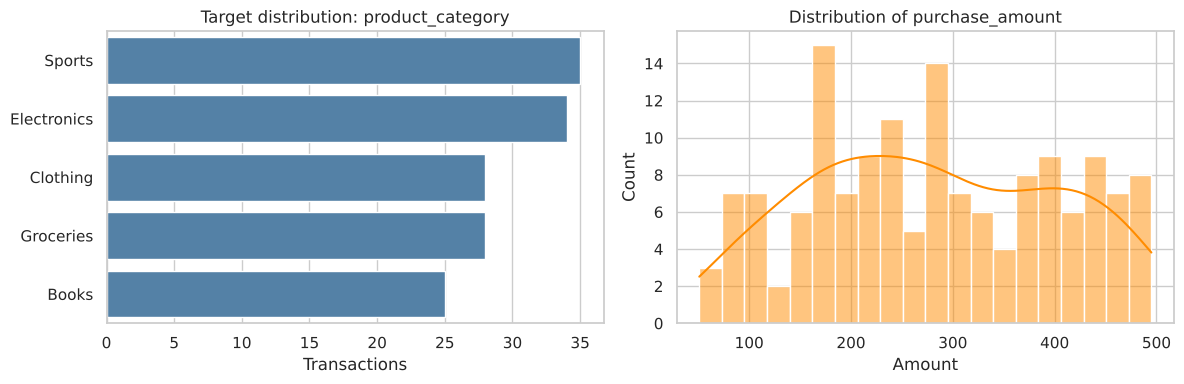

product_category
Sports         0.233
Electronics    0.227
Clothing       0.187
Groceries      0.187
Books          0.167
Name: proportion, dtype: float64


In [7]:
fig, ax = plt.subplots(1,2, figsize=(12,4))
order = final.product_category.value_counts().index
sns.countplot(data=final, y='product_category', order=order, ax=ax[0], color='steelblue')
ax[0].set_title('Target distribution: product_category'); ax[0].set_xlabel('Transactions'); ax[0].set_ylabel('')
sns.histplot(final.purchase_amount, bins=20, kde=True, ax=ax[1], color='darkorange')
ax[1].set_title('Distribution of purchase_amount'); ax[1].set_xlabel('Amount')
plt.tight_layout(); plt.savefig('../figures/eda_target_amount.png', dpi=120); plt.show()
print(final.product_category.value_counts(normalize=True).round(3))

**Interpretation:** the target is reasonably balanced (Sports 23% … Books 17%), so plain accuracy is meaningful, though macro-F1 should still be reported. Purchase amounts are roughly uniform between ~50 and ~500 (no heavy skew).

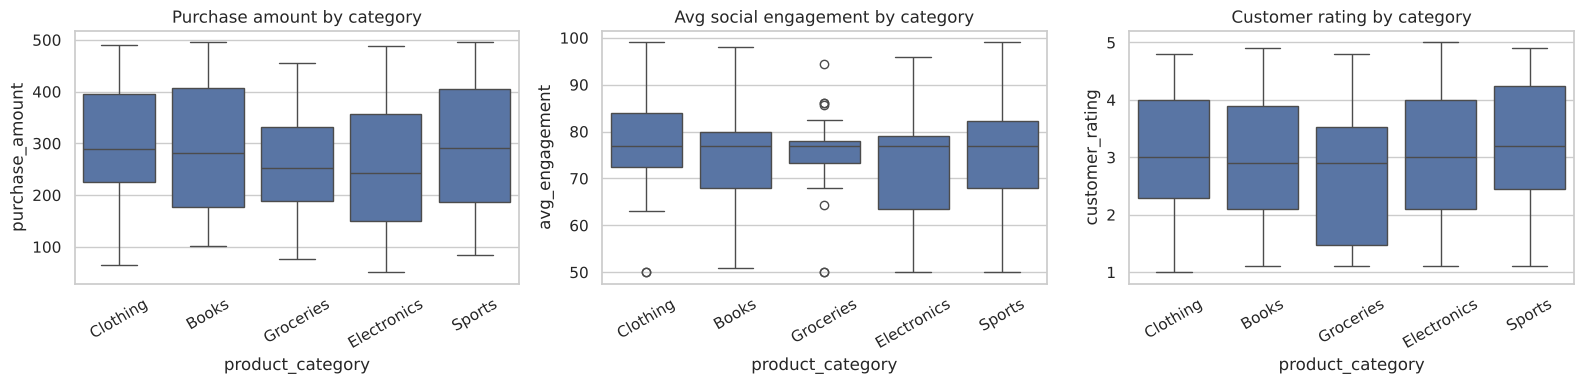

IQR outliers in purchase_amount: 0


In [8]:
fig, ax = plt.subplots(1,3, figsize=(16,4))
sns.boxplot(data=final, x='product_category', y='purchase_amount', ax=ax[0]); ax[0].set_title('Purchase amount by category')
sns.boxplot(data=final, x='product_category', y='avg_engagement', ax=ax[1]); ax[1].set_title('Avg social engagement by category')
sns.boxplot(data=final, x='product_category', y='customer_rating', ax=ax[2]); ax[2].set_title('Customer rating by category')
for a in ax: a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig('../figures/eda_boxplots.png', dpi=120); plt.show()
Q1,Q3 = final.purchase_amount.quantile([.25,.75]); I=Q3-Q1
print('IQR outliers in purchase_amount:', ((final.purchase_amount<Q1-1.5*I)|(final.purchase_amount>Q3+1.5*I)).sum())

**Interpretation:** the boxplots show strongly overlapping distributions across categories and no IQR outliers, so no single numeric feature separates categories well; we expect a modest-accuracy model and should say so honestly in the report.

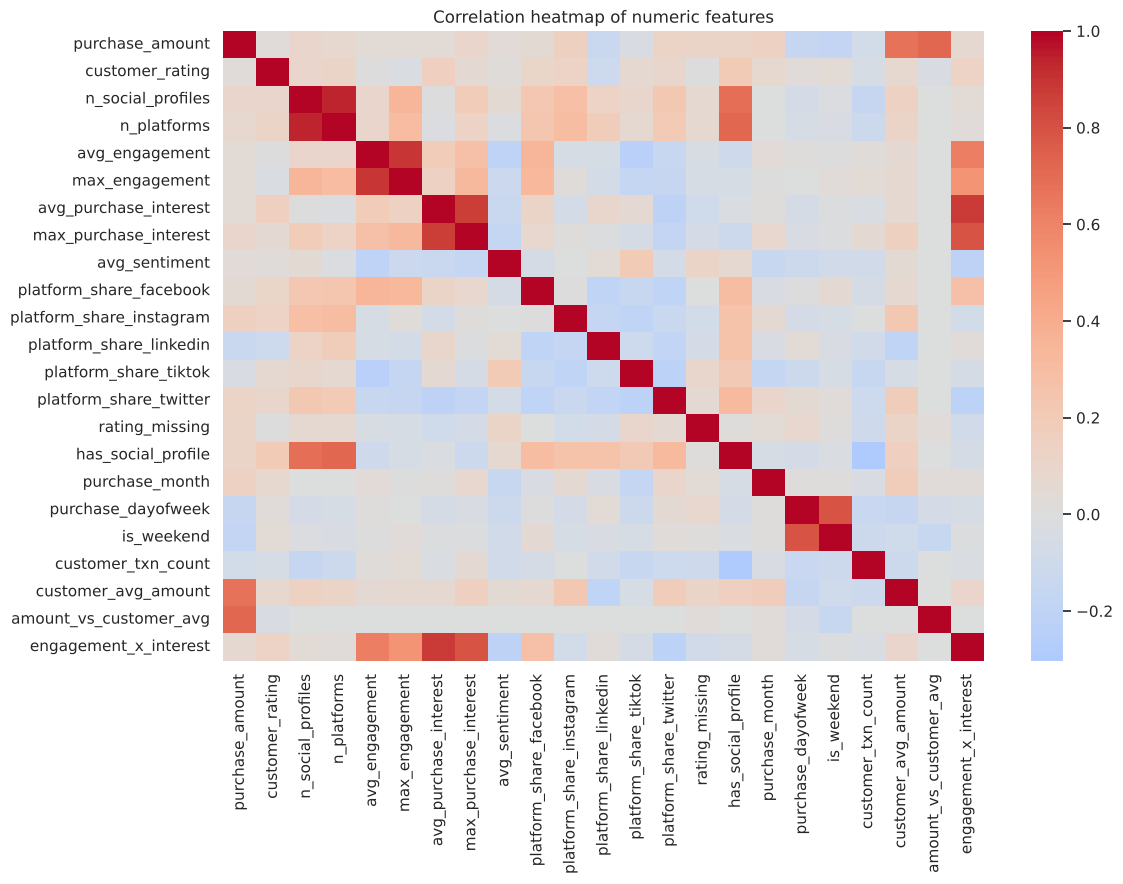

n_platforms             n_social_profiles        0.94
avg_engagement          max_engagement           0.89
avg_purchase_interest   engagement_x_interest    0.88
                        max_purchase_interest    0.87
engagement_x_interest   max_purchase_interest    0.79
is_weekend              purchase_dayofweek       0.79
amount_vs_customer_avg  purchase_amount          0.72
has_social_profile      n_platforms              0.72
dtype: float64


In [9]:
num = final.select_dtypes('number').drop(columns=['customer_id','transaction_id'])
plt.figure(figsize=(12,9)); sns.heatmap(num.corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Correlation heatmap of numeric features'); plt.tight_layout(); plt.savefig('../figures/eda_corr.png', dpi=120); plt.show()
c = num.corr().abs().where(~np.eye(len(num.columns),dtype=bool)).stack().sort_values(ascending=False)
print(c[c.index.get_level_values(0) < c.index.get_level_values(1)].head(8).round(2))

**Interpretation:** `avg_engagement`/`max_engagement`, `avg_purchase_interest`/`max_purchase_interest` and `n_social_profiles`/`n_platforms` (r≈0.94) are highly correlated, and `engagement_x_interest` is largely redundant with its inputs. Linear models may want one of each pair; tree models are unaffected.

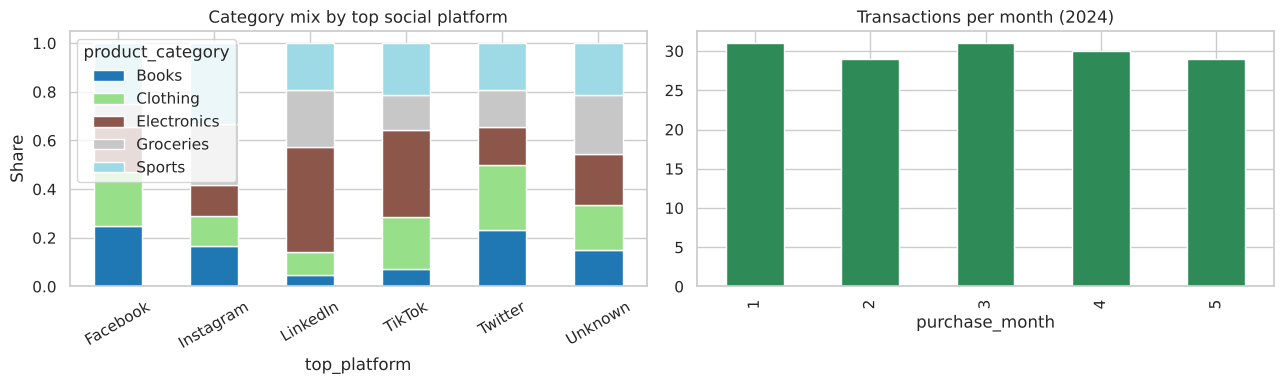

In [10]:
fig, ax = plt.subplots(1,2, figsize=(13,4))
pd.crosstab(final.top_platform, final.product_category, normalize='index').plot(kind='bar', stacked=True, ax=ax[0], colormap='tab20')
ax[0].set_title('Category mix by top social platform'); ax[0].set_ylabel('Share'); ax[0].tick_params(axis='x', rotation=30)
final.groupby('purchase_month').size().plot(kind='bar', ax=ax[1], color='seagreen'); ax[1].set_title('Transactions per month (2024)')
plt.tight_layout(); plt.savefig('../figures/eda_platform_time.png', dpi=120); plt.show()

**Interpretation:** category mix differs somewhat by platform, but with only ~150 transactions per-cell counts are small, so these differences may be noise. Data covers Jan–May 2024 only (one transaction per day), so seasonality can't be learned.

## 6. Save output

In [11]:
dp.main()
chk = pd.read_csv('../data/merged_dataset.csv'); print(chk.shape); chk.head()

social raw rows: 155 -> after de-dup: 150 (5 removed)
unique customers  social: 84 | transactions: 75
transactions with a social match: 117 / 150
saved /home/claude/proj/data/merged_dataset.csv  shape=(150, 36)
product_category
Sports         35
Electronics    34
Clothing       28
Groceries      28
Books          25
Name: count, dtype: int64
(150, 36)


,customer_id,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,n_social_profiles,n_platforms,avg_engagement,max_engagement,...,engagement_x_interest,top_platform_Facebook,top_platform_Instagram,top_platform_LinkedIn,top_platform_TikTok,top_platform_Twitter,top_platform_Unknown,amount_high,amount_low,amount_medium
0,100,1113,172,2024-04-22,Clothing,4.0,2.0,2.0,77.0,81.0,...,338.8,0,1,0,0,0,0,0,1,0
1,100,1147,387,2024-05-26,Books,4.6,2.0,2.0,77.0,81.0,...,338.8,0,1,0,0,0,0,1,0,0
2,101,1017,271,2024-01-17,Books,2.1,1.0,1.0,68.0,68.0,...,68.0,0,0,0,0,1,0,0,0,1
3,101,1021,192,2024-01-21,Groceries,3.4,1.0,1.0,68.0,68.0,...,68.0,0,0,0,0,1,0,0,1,0
4,101,1059,408,2024-02-28,Books,2.5,1.0,1.0,68.0,68.0,...,68.0,0,0,0,0,1,0,1,0,0


## 7. Limitations
- Only 150 labelled rows and 75 customers → the same customer appears in several rows; when splitting train/test use **GroupShuffleSplit on `customer_id`** to avoid leakage, or at least report this.
- 33 rows (22%) rely on imputed social features.
- Social features have weak signal; expect modest accuracy.